# C02d2 — FZ-118 on native Ghostbuster and RAID human–AI pairs

This notebook replaces the detector-training corpus used by C02d. It keeps the
complete FZ-118 representation—including meaningful ratios such as words per
sentence—but removes the easiest corpus-construction shortcut: systematic differences
in total document scale between the human and AI classes.

## Design

- **RAID:** pair rows by the released `source_id`, which identifies the human source
  used for a generation.
- **Ghostbuster:** pair files by domain and filename stem across `human/` and the
  released generator directories.
- Select exactly one AI text per human source, so a human document is not duplicated
  against many generations.
- Among available outputs, select a comparable-scale generation using word, character,
  and sentence counts. This defines a conditional experiment; it is not intended to
  estimate detector accuracy on the unfiltered web.
- Split by the native source group before any model fitting. A human source and every
  associated generation can never cross splits.
- Gate freezing on direct held-out scale balance, measured with absolute standardized
  mean differences. Keep a nuisance-only detector as a diagnostic for residual
  nonlinear or multivariate separability; it does not decide whether training runs.
- Report combined held-out performance and leave-one-dataset-out transfer.

The old ALISON/TuringBench split and all C02e intervention outputs are excluded.

Sources: [Ghostbuster data](https://github.com/vivek3141/ghostbuster-data),
[Ghostbuster paper](https://aclanthology.org/2024.naacl-long.95/),
[RAID data](https://github.com/liamdugan/raid), and
[RAID paper](https://aclanthology.org/2024.acl-long.674/).


In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import math
import pickle
import random
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/home/user/Downloads/TemporalContextResearch")
REPRO_ROOT = PROJECT_ROOT / "reproduction"
OUT = REPRO_ROOT / "results" / "causal" / "C02d2_fz118_ghostbuster_raid"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# This is a compute cap, not a statistical stopping rule. Each selected pair yields
# one untouched human row and one native AI generation.
PAIR_CAP_PER_DATASET = 1500
MIN_WORDS = 80
MAX_SCALE_RATIO = 1.25
MAX_ABSOLUTE_STANDARDIZED_MEAN_DIFFERENCE = 0.20
NUISANCE_AUC_WARNING = 0.65

# Optional explicit overrides. Leave as None to use automatic discovery.
GHOSTBUSTER_ROOT_OVERRIDE = None
RAID_TABLE_OVERRIDE = None

print("OUT:", OUT)
print("pairs per dataset cap:", PAIR_CAP_PER_DATASET)
print("per-coordinate scale ratio bound:", (1 / MAX_SCALE_RATIO, MAX_SCALE_RATIO))


OUT: ../results/causal/C02d2_fz118_ghostbuster_raid
pairs per dataset cap: 1500
per-coordinate scale ratio bound: (0.8, 1.25)


## 1. Dependencies and frozen low-level resources

The notebook does not download either dataset. It searches the existing project
checkout and prints every resolved input path. Package installation, if needed, is
performed from a notebook cell rather than a terminal.


In [2]:
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "sklearn": "scikit-learn",
    "pyarrow": "pyarrow",
    "requests": "requests",
    "raid": "raid-bench",
}
missing = [pip_name for module_name, pip_name in required.items()
           if importlib.util.find_spec(module_name) is None]

print("missing:", missing)
if missing:
    print("Run this in the current kernel, restart, and rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))
assert not missing, "Install the packages printed above, restart, and rerun."

import requests
import spacy
import textstat

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    print("Run this notebook cell once, restart, and rerun:")
    print("!python -m spacy download en_core_web_sm")
    raise

GOOGLE_WORDS_PATH = OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)
if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [x.strip().lower() for x in
                GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
                if x.strip()]
assert len(google_words) >= 10000
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}
print("spaCy:", spacy.__version__)
print("frequency SHA256:", hashlib.sha256(GOOGLE_WORDS_PATH.read_bytes()).hexdigest())


missing: []


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


spaCy: 3.8.16
frequency SHA256: 9c965d384526facc59260e94f8ccff1582633fa385004abe1455ed457062acbc


## 2. Locate the existing dataset releases

Ghostbuster is expected to contain `essay/`, `wp/`, and `reuter/` directories.
RAID is expected to provide the non-adversarial training table `train_none.csv`
(or a CSV/Parquet training table containing an `attack` column that can be filtered).


In [3]:
def first_existing_directory(candidates, required_children):
    for candidate in candidates:
        candidate = Path(candidate)
        if candidate.is_dir() and all((candidate / child).exists() for child in required_children):
            return candidate
    return None


ghostbuster_candidates = [
    PROJECT_ROOT / "external" / "ghostbuster-data-paper",
    PROJECT_ROOT / "external" / "ghostbuster-data",
    REPRO_ROOT / "external" / "ghostbuster-data-paper",
    REPRO_ROOT / "external" / "ghostbuster-data",
]
if GHOSTBUSTER_ROOT_OVERRIDE is not None:
    ghostbuster_candidates.insert(0, Path(GHOSTBUSTER_ROOT_OVERRIDE))

GHOSTBUSTER_ROOT = first_existing_directory(
    ghostbuster_candidates,
    ["essay/human", "wp/human", "reuter/human"],
)
if GHOSTBUSTER_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Ghostbuster. Checked:\n" +
        "\n".join(map(str, ghostbuster_candidates))
    )

raid_roots = [
    PROJECT_ROOT / "external" / "raid",
    PROJECT_ROOT / "external" / "RAID",
    REPRO_ROOT / "external" / "raid",
    REPRO_ROOT / "external" / "RAID",
]


def table_columns(path):
    path = Path(path)
    try:
        if ".csv" in path.name.lower():
            return set(pd.read_csv(path, nrows=0).columns)
        if path.suffix.lower() == ".parquet":
            import pyarrow.parquet as pq
            return set(pq.ParquetFile(path).schema.names)
    except Exception:
        return set()
    return set()


required_raid_columns = {"source_id", "model", "domain", "generation"}


def is_safe_raid_table(path):
    # Accept a local RAID table only when attacks can be excluded unambiguously.
    columns = table_columns(path)
    has_required_content = required_raid_columns.issubset(columns)
    explicitly_clean_partition = "train_none" in Path(path).name.lower()
    return has_required_content and ("attack" in columns or explicitly_clean_partition)
raid_candidates = []
if RAID_TABLE_OVERRIDE is not None:
    raid_candidates.append(Path(RAID_TABLE_OVERRIDE))

# Exact conventional paths first.
for root in raid_roots:
    for name in ["train_none.csv", "train_none.csv.gz", "train.csv", "train.csv.gz",
                 "train_none.parquet", "train.parquet"]:
        raid_candidates.append(root / name)

# Then search the whole project for renamed checkouts such as RAID-main,
# raid-bench, data/raid_train.csv, or Hugging Face-style Parquet shards.
search_roots = [
    PROJECT_ROOT,
    Path.home() / "Downloads",
    Path.home() / ".cache" / "huggingface" / "hub" / "datasets--liamdugan--raid",
]
search_patterns = [
    "**/train_none.csv", "**/train_none.csv.gz",
    "**/train_none.parquet", "**/train.csv", "**/train.csv.gz",
    "**/train.parquet", "**/*raid*train*.csv", "**/*raid*train*.csv.gz",
    "**/*raid*train*.parquet", "**/train-*-of-*.parquet",
]
for root in search_roots:
    if root.is_dir():
        for pattern in search_patterns:
            raid_candidates.extend(root.glob(pattern))

raid_candidates = sorted(
    {Path(p).resolve() for p in raid_candidates if Path(p).is_file()},
    key=lambda p: (
        0 if "train_none" in p.name.lower() else 1,
        0 if "raid" in str(p).lower() else 1,
        -p.stat().st_size,
        str(p),
    ),
)
valid_raid_candidates = [
    path for path in raid_candidates
    if is_safe_raid_table(path)
]

RAID_TABLE = valid_raid_candidates[0] if valid_raid_candidates else None
if RAID_TABLE is not None:
    RAID_SOURCE_KIND = "local_table"
    RAID_FRAME = None
    # If discovery landed on one Hugging Face shard, consume every sibling shard.
    shard_match = re.fullmatch(r"train-\d+-of-\d+\.parquet", RAID_TABLE.name)
    if shard_match:
        RAID_TABLES = sorted(RAID_TABLE.parent.glob("train-*-of-*.parquet"))
    else:
        RAID_TABLES = [RAID_TABLE]
else:
    # Official package fallback. This reuses the RAID cache when present and otherwise
    # retrieves only the non-adversarial training partition—not the 11.8 GB attack set.
    from raid.utils import load_data
    print("No raw RAID table found; using raid-bench load_data(train, no adversarial).")
    RAID_FRAME = load_data(split="train", include_adversarial=False)
    missing_columns = required_raid_columns - set(RAID_FRAME.columns)
    if missing_columns:
        raise ValueError(f"Official RAID loader is missing columns: {sorted(missing_columns)}")
    RAID_SOURCE_KIND = "raid_bench_loader"
    RAID_TABLES = []

print("Ghostbuster:", GHOSTBUSTER_ROOT)
print("RAID source:", RAID_SOURCE_KIND)
if RAID_TABLES:
    print("RAID table(s):")
    for path in RAID_TABLES:
        print(" -", path)
else:
    print("RAID rows loaded:", len(RAID_FRAME))


No raw RAID table found; using raid-bench load_data(train, no adversarial).
Ghostbuster: /home/user/Downloads/TemporalContextResearch/external/ghostbuster-data-paper
RAID source: raid_bench_loader
RAID rows loaded: 467985


## 3. Shared scale measurements

These measurements are used only to construct comparable-scale pairs and audit the
result. They do not replace the richer FZ-118 representation.


In [4]:
WORD_RE = re.compile(r"\b[A-Za-z]+(?:['’][A-Za-z]+)?\b")
SENTENCE_RE = re.compile(r"[.!?]+(?:[\"'’”)]*)?(?:\s|$)")


def cheap_scale(text):
    text = str(text).strip()
    words = WORD_RE.findall(text)
    sentences = max(1, len(SENTENCE_RE.findall(text)))
    return {
        "n_characters": len(text),
        "n_words": len(words),
        "n_sentences": sentences,
    }


def scale_distance(human_text, ai_text):
    human = cheap_scale(human_text)
    ai = cheap_scale(ai_text)
    if min(human.values()) <= 0 or min(ai.values()) <= 0:
        return math.inf, human, ai
    ratios = {
        key: ai[key] / human[key]
        for key in ["n_characters", "n_words", "n_sentences"]
    }
    within_bound = all(
        1 / MAX_SCALE_RATIO <= value <= MAX_SCALE_RATIO
        for value in ratios.values()
    )
    distance = math.sqrt(sum(math.log(value) ** 2 for value in ratios.values()))
    return (distance if within_bound else math.inf), human, ai


def stable_hash(*parts):
    return hashlib.sha256("|".join(map(str, parts)).encode("utf-8")).hexdigest()


## 4. Recover native Ghostbuster pairs

The filename stem is the released source link. For each human file, the closest-scale
eligible output is chosen from the released direct generator directories. Prompt and
generator identity remain recorded for later stratified analysis.


In [5]:
GHOSTBUSTER_DOMAINS = {
    "essay": "student_essay",
    "wp": "creative_writing",
    "reuter": "news",
}
GHOSTBUSTER_GENERATORS = [
    "gpt", "claude", "gpt_prompt1", "gpt_prompt2", "gpt_semantic", "gpt_writing"
]


def load_ghostbuster_pairs(root):
    rows = []
    audit = []
    for folder, domain in GHOSTBUSTER_DOMAINS.items():
        domain_root = root / folder
        human_files = sorted((domain_root / "human").glob("*.txt"))
        for human_path in human_files:
            human_text = human_path.read_text(encoding="utf-8", errors="replace").strip()
            if cheap_scale(human_text)["n_words"] < MIN_WORDS:
                continue
            candidates = []
            for generator in GHOSTBUSTER_GENERATORS:
                ai_path = domain_root / generator / human_path.name
                if not ai_path.is_file():
                    continue
                ai_text = ai_path.read_text(encoding="utf-8", errors="replace").strip()
                distance, human_scale, ai_scale = scale_distance(human_text, ai_text)
                candidates.append((distance, stable_hash(SEED, folder, human_path.stem, generator),
                                   generator, ai_path, ai_text, human_scale, ai_scale))
            eligible = [x for x in candidates if np.isfinite(x[0])]
            if not eligible:
                audit.append({"dataset": "ghostbuster", "domain": domain,
                              "native_id": human_path.stem, "status": "no_scale_match"})
                continue
            chosen = min(eligible, key=lambda x: (x[0], x[1]))
            distance, _, generator, ai_path, ai_text, human_scale, ai_scale = chosen
            rows.append({
                "dataset": "ghostbuster",
                "domain": domain,
                "native_source_id": f"{folder}/{human_path.stem}",
                "generator": generator,
                "generation_config": generator,
                "human_text": human_text,
                "ai_text": ai_text,
                "human_path": str(human_path),
                "ai_path": str(ai_path),
                "scale_distance": distance,
                **{f"human_{k}": v for k, v in human_scale.items()},
                **{f"ai_{k}": v for k, v in ai_scale.items()},
            })
    return pd.DataFrame(rows), pd.DataFrame(audit)


ghostbuster_pairs, ghostbuster_rejections = load_ghostbuster_pairs(GHOSTBUSTER_ROOT)
assert len(ghostbuster_pairs) > 0
display(ghostbuster_pairs.groupby(["domain", "generator"]).size().rename("pairs").to_frame())
print("eligible Ghostbuster pairs:", len(ghostbuster_pairs))
print("scale-rejected Ghostbuster sources:", len(ghostbuster_rejections))


pairs
domain           generator          
creative_writing claude           78
                 gpt              66
                 gpt_prompt1      36
                 gpt_prompt2      39
                 gpt_semantic     57
                 gpt_writing      18
student_essay    claude           96
                 gpt              42
                 gpt_prompt1      35
                 gpt_prompt2      38
                 gpt_semantic     59
                 gpt_writing      74

eligible Ghostbuster pairs: 638
scale-rejected Ghostbuster sources: 1362


## 5. Recover native RAID pairs without loading the full release at once

RAID explicitly records the human-source UUID in `source_id`. The loader makes two
streaming passes over CSV files: first to choose human sources, then to retrieve their
non-adversarial generations. For each source, a generator is selected deterministically
and its closest-scale decoding configuration is retained.


In [6]:
RAID_COLUMNS = [
    "id", "source_id", "model", "decoding", "repetition_penalty",
    "attack", "domain", "generation",
]
RAID_ENGLISH_DOMAINS = {
    "abstracts", "books", "news", "poetry", "recipes", "reddit", "reviews", "wiki"
}


def raid_chunks(paths, chunksize=100_000):
    if RAID_FRAME is not None:
        for start in range(0, len(RAID_FRAME), chunksize):
            chunk = RAID_FRAME.iloc[start:start + chunksize].copy()
            for column in RAID_COLUMNS:
                if column not in chunk.columns:
                    chunk[column] = None
            yield chunk[RAID_COLUMNS]
        return
    for raw_path in paths:
        path = Path(raw_path)
        available = table_columns(path)
        if "attack" not in available and "train_none" not in path.name.lower():
            raise ValueError(
                f"Refusing RAID table without attack provenance: {path}. "
                "Use train_none or a table with an attack column."
            )
        if ".csv" in path.name:
            iterator = pd.read_csv(
                path,
                usecols=lambda c: c in RAID_COLUMNS,
                chunksize=chunksize,
                low_memory=False,
            )
        elif path.suffix == ".parquet":
            iterator = [pd.read_parquet(
                path,
                columns=[c for c in RAID_COLUMNS if c in available],
            )]
        else:
            raise ValueError(f"Unsupported RAID table: {path}")
        for chunk in iterator:
            for column in RAID_COLUMNS:
                if column not in chunk.columns:
                    chunk[column] = None
            yield chunk[RAID_COLUMNS]


def normalized_attack(series):
    return series.fillna("none").astype(str).str.lower().str.strip()


NON_ADVERSARIAL_ATTACK_LABELS = {"none", ""}


# Pass 1: collect released human rows, then take a deterministic oversample so enough
# sources survive the strict scale-match filter.
human_parts = []
for chunk in tqdm(raid_chunks(RAID_TABLES), desc="RAID pass 1: human rows"):
    chunk["model"] = chunk["model"].fillna("human").astype(str).str.lower()
    chunk["domain"] = chunk["domain"].astype(str).str.lower()
    chunk["attack"] = normalized_attack(chunk["attack"])
    keep = (
        chunk["model"].eq("human")
        & chunk["attack"].isin(NON_ADVERSARIAL_ATTACK_LABELS)
        & chunk["domain"].isin(RAID_ENGLISH_DOMAINS)
    )
    human_parts.append(chunk.loc[keep, ["id", "source_id", "domain", "generation"]])

raid_humans = pd.concat(human_parts, ignore_index=True)
raid_humans["source_id"] = raid_humans["source_id"].fillna(raid_humans["id"]).astype(str)
raid_humans = raid_humans.drop_duplicates("source_id")
raid_humans["_hash"] = [stable_hash(SEED, "raid-source", x) for x in raid_humans["source_id"]]
raid_humans = raid_humans.sort_values("_hash").head(PAIR_CAP_PER_DATASET * 3)
chosen_raid_sources = set(raid_humans["source_id"])

# Pass 2: retrieve non-adversarial generations only for the chosen native sources.
generation_parts = []
raid_generation_rows_scanned = 0
raid_adversarial_generation_rows_excluded = 0
for chunk in tqdm(raid_chunks(RAID_TABLES), desc="RAID pass 2: generations"):
    chunk["source_id"] = chunk["source_id"].fillna(chunk["id"]).astype(str)
    chunk["model"] = chunk["model"].fillna("human").astype(str).str.lower()
    chunk["attack"] = normalized_attack(chunk["attack"])
    candidate_generation = (
        chunk["source_id"].isin(chosen_raid_sources)
        & ~chunk["model"].eq("human")
    )
    clean_attack = chunk["attack"].isin(NON_ADVERSARIAL_ATTACK_LABELS)
    raid_generation_rows_scanned += int(candidate_generation.sum())
    raid_adversarial_generation_rows_excluded += int(
        (candidate_generation & ~clean_attack).sum()
    )
    keep = candidate_generation & clean_attack
    generation_parts.append(chunk.loc[keep, RAID_COLUMNS])

raid_generations = pd.concat(generation_parts, ignore_index=True)
assert raid_generations["attack"].isin(NON_ADVERSARIAL_ATTACK_LABELS).all()
print("candidate RAID humans:", len(raid_humans))
print("candidate RAID generations:", len(raid_generations))
print("RAID adversarial generations excluded:", raid_adversarial_generation_rows_excluded)


RAID pass 1: human rows: 5it [00:00, 92.82it/s]
RAID pass 2: generations: 5it [00:00, 16.23it/s]

candidate RAID humans: 4500
candidate RAID generations: 153000
RAID adversarial generations excluded: 0


In [7]:
def choose_raid_pairs(humans, generations):
    human_lookup = humans.set_index("source_id")
    rows = []
    rejections = []
    for source_id, candidates in tqdm(generations.groupby("source_id"),
                                      desc="RAID native pairing"):
        if source_id not in human_lookup.index:
            continue
        human_row = human_lookup.loc[source_id]
        human_text = str(human_row["generation"]).strip()
        if cheap_scale(human_text)["n_words"] < MIN_WORDS:
            continue

        available_models = sorted(candidates["model"].dropna().astype(str).unique())
        if not available_models:
            continue
        # Deterministic model choice prevents the length matcher from collapsing onto
        # whichever model happens to imitate human document length best globally.
        chosen_model = min(
            available_models,
            key=lambda model: stable_hash(SEED, "raid-model", source_id, model),
        )
        model_rows = candidates[candidates["model"].astype(str).eq(chosen_model)]

        scored = []
        for candidate in model_rows.itertuples(index=False):
            ai_text = str(candidate.generation).strip()
            distance, human_scale, ai_scale = scale_distance(human_text, ai_text)
            scored.append((distance, stable_hash(SEED, "raid-output", candidate.id),
                           candidate, ai_text, human_scale, ai_scale))
        eligible = [x for x in scored if np.isfinite(x[0])]
        if not eligible:
            rejections.append({"dataset": "raid", "domain": human_row["domain"],
                               "native_id": source_id, "status": "no_scale_match"})
            continue
        distance, _, candidate, ai_text, human_scale, ai_scale = min(
            eligible, key=lambda x: (x[0], x[1])
        )
        rows.append({
            "dataset": "raid",
            "domain": str(human_row["domain"]),
            "native_source_id": source_id,
            "generator": str(candidate.model),
            "attack": str(candidate.attack),
            "generation_config": (
                f"decoding={candidate.decoding};repetition_penalty={candidate.repetition_penalty}"
            ),
            "human_text": human_text,
            "ai_text": ai_text,
            "human_path": (
                ";".join(map(str, RAID_TABLES))
                if RAID_TABLES else "raid-bench:train:include_adversarial=False"
            ),
            "ai_path": (
                ";".join(map(str, RAID_TABLES))
                if RAID_TABLES else "raid-bench:train:include_adversarial=False"
            ),
            "scale_distance": distance,
            **{f"human_{k}": v for k, v in human_scale.items()},
            **{f"ai_{k}": v for k, v in ai_scale.items()},
        })
    return pd.DataFrame(rows), pd.DataFrame(rejections)


raid_pairs, raid_rejections = choose_raid_pairs(raid_humans, raid_generations)
assert len(raid_pairs) > 0
assert raid_pairs["attack"].isin(NON_ADVERSARIAL_ATTACK_LABELS).all()
display(raid_pairs.groupby(["domain", "generator"]).size().rename("pairs").to_frame())
print("eligible RAID pairs:", len(raid_pairs))
print("scale-rejected RAID sources:", len(raid_rejections))


RAID native pairing: 100%|██████████████████████████████████████████████████████████| 4500/4500 [00:08<00:00, 556.36it/s]


pairs
domain    generator          
abstracts chatgpt          16
          cohere           16
          cohere-chat      19
          gpt2             11
          gpt3              6
...                       ...
wiki      llama-chat        3
          mistral          15
          mistral-chat     27
          mpt               8
          mpt-chat         17

[87 rows x 1 columns]

eligible RAID pairs: 909
scale-rejected RAID sources: 3562


## 6. Cap, combine, and freeze group-locked splits

The cap is applied deterministically after eligibility filtering. Splits are assigned
within dataset and domain, so the class balance, dataset mixture, and domain mixture are
the same by construction. The native source—not the individual text—is the split unit.


In [8]:
def deterministic_cap(frame, n, namespace):
    frame = frame.copy()
    frame["_cap_hash"] = [stable_hash(SEED, namespace, x)
                          for x in frame["native_source_id"]]
    return frame.sort_values("_cap_hash").head(n).drop(columns="_cap_hash")


pair_table = pd.concat([
    deterministic_cap(ghostbuster_pairs, PAIR_CAP_PER_DATASET, "ghostbuster-cap"),
    deterministic_cap(raid_pairs, PAIR_CAP_PER_DATASET, "raid-cap"),
], ignore_index=True)
pair_table["pair_group_id"] = (
    pair_table["dataset"].astype(str) + ":" + pair_table["native_source_id"].astype(str)
)
pair_table = pair_table.sort_values("pair_group_id").reset_index(drop=True)
pair_table["pair_id"] = np.arange(len(pair_table), dtype=int)


def assign_splits(frame):
    output = []
    for (dataset, domain), group in frame.groupby(["dataset", "domain"], sort=True):
        group = group.copy()
        group["_split_hash"] = [stable_hash(SEED, "split", x)
                                for x in group["pair_group_id"]]
        group = group.sort_values("_split_hash").reset_index(drop=True)
        n = len(group)
        n_train = int(round(0.70 * n))
        n_valid = int(round(0.15 * n))
        group["split"] = (
            ["train"] * n_train
            + ["validation"] * n_valid
            + ["test"] * (n - n_train - n_valid)
        )
        output.append(group.drop(columns="_split_hash"))
    return pd.concat(output, ignore_index=True)


pair_table = assign_splits(pair_table)

human_rows = pair_table.rename(columns={"human_text": "text"}).copy()
human_rows["label"] = 0
human_rows["class_name"] = "human"
human_rows["source_id"] = "human__" + human_rows["pair_group_id"]

ai_rows = pair_table.rename(columns={"ai_text": "text"}).copy()
ai_rows["label"] = 1
ai_rows["class_name"] = "ai"
ai_rows["source_id"] = "ai__" + ai_rows["pair_group_id"]

corpus_columns = [
    "source_id", "pair_id", "pair_group_id", "dataset", "domain", "generator",
    "generation_config", "split", "label", "class_name", "text",
]
corpus = pd.concat([
    human_rows[corpus_columns],
    ai_rows[corpus_columns],
], ignore_index=True).sort_values(["pair_id", "label"]).reset_index(drop=True)

assert corpus.groupby("pair_id").size().eq(2).all()
assert corpus.groupby("pair_id")["label"].nunique().eq(2).all()
assert corpus.groupby("pair_id")["split"].nunique().eq(1).all()
assert corpus.groupby("pair_group_id")["split"].nunique().eq(1).all()
assert not corpus["source_id"].duplicated().any()

pair_table.to_parquet(OUT / "native_pair_table.parquet", index=False)
corpus.to_parquet(OUT / "paired_corpus.parquet", index=False)
display(corpus.groupby(["dataset", "domain", "split", "class_name"])
        .size().rename("n").to_frame())
print("frozen native pairs:", len(pair_table))


n
dataset     domain           split      class_name     
ghostbuster creative_writing test       ai           44
                                        human        44
                             train      ai          206
                                        human       206
                             validation ai           44
                                        human        44
            student_essay    test       ai           51
                                        human        51
                             train      ai          241
                                        human       241
                             validation ai           52
                                        human        52
raid        abstracts        test       ai           23
                                        human        23
                             train      ai          105
                                        human       105
                             validation ai           22
                                        human        22
            books            test       ai           18
                                        human        18
                             train      ai           84
                                        human        84
                             validation ai           18
                                        human        18
            news             test       ai           25
                                        human        25
                             train      ai          117
                                        human       117
                             validation ai           25
                                        human        25
            poetry           test       ai           10
                                        human        10
                             train      ai           46
                                        human        46
                             validation ai           10
                                        human        10
            recipes          test       ai           21
                                        human        21
                             train      ai           99
                                        human        99
                             validation ai           21
                                        human        21
            reddit           test       ai           16
                                        human        16
                             train      ai           71
                                        human        71
                             validation ai           15
                                        human        15
            reviews          test       ai            6
                                        human         6
                             train      ai           28
                                        human        28
                             validation ai            6
                                        human         6
            wiki             test       ai           19
                                        human        19
                             train      ai           86
                                        human        86
                             validation ai           18
                                        human        18

frozen native pairs: 1547


## 7. Audit trivial document-scale balance

The hard gate is the largest absolute standardized mean difference in total characters,
words, or sentences on the validation split, both combined and within each dataset.
A nuisance-only classifier is also reported, but only as a diagnostic: its multivariate
decision boundary can exploit residual distribution shape even when the direct class
balance differences are small. Ratio features are not included because quantities such
as words per sentence are part of the substantive stylistic representation.


In [9]:
scale_rows = []
for row in tqdm(corpus.itertuples(index=False), total=len(corpus), desc="scale audit"):
    stats = cheap_scale(row.text)
    scale_rows.append({
        "source_id": row.source_id,
        "pair_id": row.pair_id,
        "pair_group_id": row.pair_group_id,
        "dataset": row.dataset,
        "domain": row.domain,
        "split": row.split,
        "label": row.label,
        "class_name": row.class_name,
        **stats,
    })
scale_frame = pd.DataFrame(scale_rows)
NUISANCE_FEATURES = ["n_characters", "n_words", "n_sentences"]


def standardized_mean_difference(frame, feature):
    human = frame.loc[frame["label"].eq(0), feature].to_numpy(float)
    ai = frame.loc[frame["label"].eq(1), feature].to_numpy(float)
    pooled = math.sqrt((human.var(ddof=1) + ai.var(ddof=1)) / 2)
    return float((ai.mean() - human.mean()) / pooled) if pooled else 0.0


balance_rows = []
for split, split_frame in scale_frame.groupby("split"):
    for dataset, frame in [("combined", split_frame), *split_frame.groupby("dataset")]:
        for feature in NUISANCE_FEATURES:
            balance_rows.append({
                "split": split,
                "dataset": dataset,
                "feature": feature,
                "human_median": frame.loc[frame.label.eq(0), feature].median(),
                "ai_median": frame.loc[frame.label.eq(1), feature].median(),
                "standardized_mean_difference": standardized_mean_difference(frame, feature),
            })
balance_audit = pd.DataFrame(balance_rows)
display(balance_audit)

train_scale = scale_frame[scale_frame["split"].eq("train")]
valid_scale = scale_frame[scale_frame["split"].eq("validation")]
test_scale = scale_frame[scale_frame["split"].eq("test")]

nuisance_detector = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)),
])
nuisance_detector.fit(train_scale[NUISANCE_FEATURES], train_scale["label"])

nuisance_rows = []
for split, split_frame in [("validation", valid_scale), ("test", test_scale)]:
    evaluation_groups = {"combined": split_frame}
    evaluation_groups.update({
        str(dataset): frame for dataset, frame in split_frame.groupby("dataset")
    })
    for dataset, frame in evaluation_groups.items():
        probability = nuisance_detector.predict_proba(frame[NUISANCE_FEATURES])[:, 1]
        nuisance_rows.append({
            "split": split,
            "dataset": dataset,
            "n": len(frame),
            "auc": roc_auc_score(frame["label"], probability),
            "balanced_accuracy": balanced_accuracy_score(
                frame["label"], probability >= 0.5
            ),
        })
nuisance_summary = pd.DataFrame(nuisance_rows)
display(nuisance_summary)

validation_balance = balance_audit[balance_audit["split"].eq("validation")]
max_abs_validation_smd = float(
    validation_balance["standardized_mean_difference"].abs().max()
)
BALANCE_GATE = bool(
    max_abs_validation_smd <= MAX_ABSOLUTE_STANDARDIZED_MEAN_DIFFERENCE
)
validation_nuisance_auc = float(nuisance_summary.loc[
    nuisance_summary["split"].eq("validation")
    & nuisance_summary["dataset"].eq("combined"),
    "auc",
].iloc[0])
NUISANCE_WARNING = bool(validation_nuisance_auc >= NUISANCE_AUC_WARNING)

print(
    "scale-balance gate:", "PASS" if BALANCE_GATE else "BLOCKED",
    f"| max validation |SMD|={max_abs_validation_smd:.3f}",
    f"<= {MAX_ABSOLUTE_STANDARDIZED_MEAN_DIFFERENCE:.2f}",
)
print(
    "nuisance classifier:", "WARN" if NUISANCE_WARNING else "diagnostic only",
    f"| combined validation AUC={validation_nuisance_auc:.3f}",
)

balance_audit.to_csv(OUT / "document_scale_balance.csv", index=False)
nuisance_summary.to_csv(OUT / "nuisance_detector_summary.csv", index=False)


scale audit: 100%|████████████████████████████████████████████████████████████████| 3094/3094 [00:00<00:00, 10428.23it/s]


,split,dataset,feature,human_median,ai_median,standardized_mean_difference
0,test,combined,n_characters,1816.0,1896.0,0.056805
1,test,combined,n_words,315.0,319.0,-0.021860
2,test,combined,n_sentences,17.0,17.0,-0.029170
3,test,ghostbuster,n_characters,3342.0,3441.0,0.142698
4,test,ghostbuster,n_words,554.0,532.0,-0.051035
5,test,ghostbuster,n_sentences,29.0,28.0,-0.089767
6,test,raid,n_characters,1395.5,1418.5,0.029479
7,test,raid,n_words,230.0,225.5,-0.016674
8,test,raid,n_sentences,12.0,12.0,0.031271
9,train,combined,n_characters,1612.0,1712.0,0.071533


,split,dataset,n,auc,balanced_accuracy
0,validation,combined,462,0.649182,0.593074
1,validation,ghostbuster,192,0.732205,0.651042
2,validation,raid,270,0.585350,0.551852
3,test,combined,466,0.580817,0.553648
4,test,ghostbuster,190,0.630914,0.573684
5,test,raid,276,0.548362,0.539855


scale-balance gate: PASS | max validation |SMD|=0.158 <= 0.20
nuisance classifier: diagnostic only | combined validation AUC=0.649


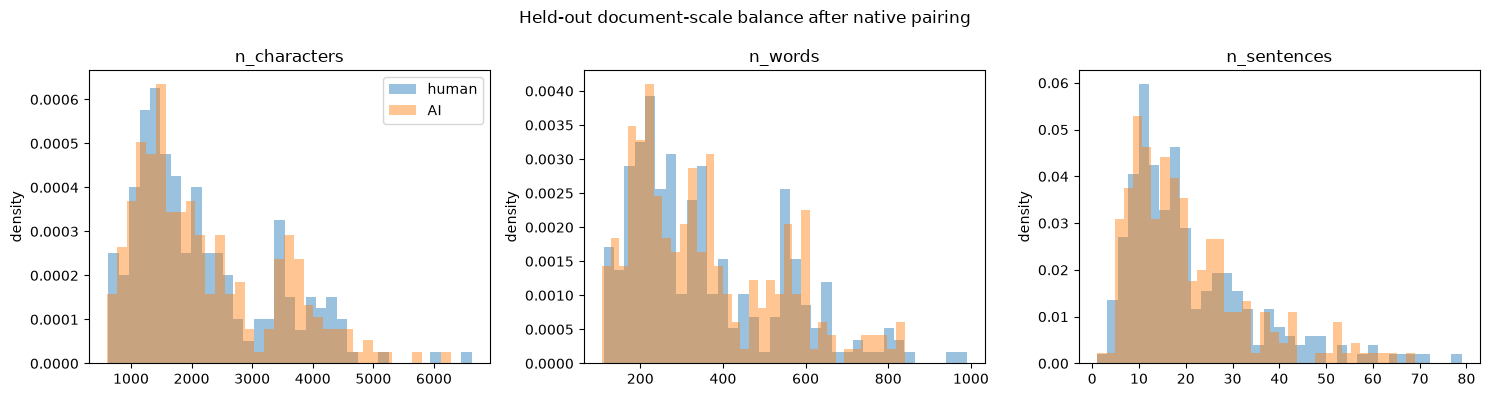

saved: ../results/causal/C02d2_fz118_ghostbuster_raid/heldout_document_scale_balance.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, feature in zip(axes, NUISANCE_FEATURES):
    for label, name, color in [(0, "human", "tab:blue"), (1, "AI", "tab:orange")]:
        values = test_scale.loc[test_scale["label"].eq(label), feature].to_numpy(float)
        axis.hist(values, bins=35, density=True, alpha=0.45, label=name, color=color)
    axis.set_title(feature)
    axis.set_ylabel("density")
axes[0].legend()
fig.suptitle("Held-out document-scale balance after native pairing")
fig.tight_layout()
figure_path = OUT / "heldout_document_scale_balance.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print("saved:", figure_path)


## 8. Freeze the complete FZ-118 contract

No coordinate is removed. The dataset construction—not feature censorship—prevents
raw scale from becoming an easy class shortcut. Meaningful normalized quantities such
as characters per word and words per sentence remain available.


In [11]:
PUNCTUATION = [
    ("comma", ","),
    ("period", "."),
    ("colon", ":"),
    ("semicolon", ";"),
    ("question", "?"),
    ("exclamation", "!"),
    ("hyphen", "-"),
    ("quote", '"'),
    ("lparen", "("),
    ("rparen", ")"),
    ("lbracket", "["),
    ("rbracket", "]"),
    ("newline", "\n"),
]

FEATURE_NAMES = [
    "n_characters", "n_syllables", "n_words", "n_sentences",
    "n_difficult_words", "n_short_words", "n_long_words",
    "characters_per_word", "syllables_per_word", "words_per_sentence",
    "share_difficult_words", "share_short_words", "share_long_words",
    "automated_readability_index", "coleman_liau_index",
    "flesch_kincaid_grade", "flesch_reading_ease", "gunning_fog",
    "lix", "mcalpine_eflaw", "rix", "smog_grade",
    "share_stopwords", "share_unique_words",
    "share_google_top100", "share_google_top1000", "share_google_top10000",
]

FEATURE_NAMES += [f"punct_relative_{name}" for name, _ in PUNCTUATION]
FEATURE_NAMES += [f"punct_per_sentence_{name}" for name, _ in PUNCTUATION]
FEATURE_NAMES += ["n_paragraphs", "mean_paragraph_words"]

for family in ["word", "pos"]:
    for n in [1, 2, 3]:
        FEATURE_NAMES += [
            f"{family}_{n}gram_overlap_bin_{i}"
            for i in range(10)
        ]

FEATURE_NAMES += [
    "and_conjunction_word_unigram_overlap",
    "and_conjunction_word_bigram_overlap",
    "and_conjunction_word_trigram_overlap",
]

assert len(FEATURE_NAMES) == 118

FEATURE_BLOCKS = {
    "basic_absolute": list(range(0, 7)),
    "basic_relative": list(range(7, 13)),
    "readability": list(range(13, 22)),
    "lexical_diversity": list(range(22, 27)),
    "punctuation_relative": list(range(27, 40)),
    "punctuation_per_sentence": list(range(40, 53)),
    "paragraph": list(range(53, 55)),
    "word_sentence_overlap": list(range(55, 85)),
    "pos_sentence_overlap": list(range(85, 115)),
    "conjunction_overlap": list(range(115, 118)),
}

assert sorted(sum(FEATURE_BLOCKS.values(), [])) == list(range(118))

feature_contract = {
    "name": "FZ-118",
    "source_indices": [0, 117],
    "n_features": 118,
    "feature_names": FEATURE_NAMES,
    "feature_blocks": FEATURE_BLOCKS,
    "short_word_max_characters": 3,
    "long_word_min_characters": 7,
    "overlap": "multiset intersection / smaller ngram multiset",
    "histograms": "10 uniform bins on [0,1], normalized by adjacent-sentence-pair count",
    "quote_policy": "straight plus left/right curly double quotes",
    "human_target": "untouched detector-training humans",
}

with open(OUT / "fz118_feature_contract.json", "w") as f:
    json.dump(feature_contract, f, indent=2)

display(pd.DataFrame({
    "block": FEATURE_BLOCKS.keys(),
    "n_features": [len(v) for v in FEATURE_BLOCKS.values()],
}))


,block,n_features
0,basic_absolute,7
1,basic_relative,6
2,readability,9
3,lexical_diversity,5
4,punctuation_relative,13
5,punctuation_per_sentence,13
6,paragraph,2
7,word_sentence_overlap,30
8,pos_sentence_overlap,30
9,conjunction_overlap,3


In [12]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


## 9. Extract and cache FZ-118

The cache is namespaced to this paired corpus and cannot reuse the earlier C02d feature
matrix.


In [22]:
LAYOUT_NORMALIZATION_VERSION = "newline_to_space_v1"


def normalize_detector_text(text):
    """Remove paragraph formatting without changing the textual content."""
    return str(text).translate(
        str.maketrans({
            "\n": " ",
            "\r": " ",
        })
    )


FEATURE_PATH = OUT / "fz118_paired_features.parquet"
fingerprint_path = OUT / "paired_corpus_sha256.txt"

# Including the normalization version invalidates the old feature cache.
corpus_fingerprint = hashlib.sha256(
    (
        LAYOUT_NORMALIZATION_VERSION
        + "\n"
        + corpus[["source_id", "text"]].to_csv(index=False)
    ).encode("utf-8")
).hexdigest()

cache_valid = (
    FEATURE_PATH.exists()
    and fingerprint_path.exists()
    and fingerprint_path.read_text().strip() == corpus_fingerprint
)

if cache_valid:
    features = pd.read_parquet(FEATURE_PATH)
    print("loaded normalized FZ-118 feature cache")
else:
    rows = []

    for row in tqdm(
        corpus.itertuples(index=False),
        total=len(corpus),
        desc="FZ-118 after layout normalization",
    ):
        normalized_text = normalize_detector_text(row.text)
        vector = extract_fz118(normalized_text)

        output = {
            "source_id": row.source_id,
            "pair_id": int(row.pair_id),
            "pair_group_id": row.pair_group_id,
            "dataset": row.dataset,
            "domain": row.domain,
            "generator": row.generator,
            "split": row.split,
            "label": int(row.label),
            "class_name": row.class_name,
        }

        output.update(dict(zip(FEATURE_NAMES, vector)))
        rows.append(output)

    features = pd.DataFrame(rows)

    features.to_parquet(
        FEATURE_PATH,
        index=False,
    )
    fingerprint_path.write_text(
        corpus_fingerprint + "\n"
    )

assert len(features) == len(corpus)
assert features.groupby("pair_id").size().eq(2).all()
assert np.isfinite(
    features[FEATURE_NAMES].to_numpy(float)
).all()

# Every document must now be represented as one paragraph.
assert features["n_paragraphs"].eq(1).all()
assert features["punct_relative_newline"].eq(0).all()
assert features["punct_per_sentence_newline"].eq(0).all()

print("feature matrix:", features[FEATURE_NAMES].shape)
print("layout normalization:", LAYOUT_NORMALIZATION_VERSION)
print("feature-cache SHA256:", corpus_fingerprint)
print(
    "paragraph counts:",
    features["n_paragraphs"].value_counts().to_dict(),
)

FZ-118 after layout normalization: 100%|█████████████████████████████████████████████| 3094/3094 [02:10<00:00, 23.72it/s]


feature matrix: (3094, 118)
layout normalization: newline_to_space_v1
feature-cache SHA256: 9b458915873628b82640a8367b07ea3c1d0937c063ad60b1fbe34e14fd683fff
paragraph counts: {1.0: 3094}


## 10. Train and freeze the detector only after the scale-balance gate

Candidate model selection uses the validation pairs. The test split remains untouched
until the model family is frozen.


In [23]:
if not BALANCE_GATE:
    raise RuntimeError(
        "Maximum validation absolute standardized mean difference exceeds the "
        "frozen scale-balance ceiling. Tighten the pair-scale bound or inspect "
        "the dataset loaders before fitting FZ-118."
    )

train_df = features[features["split"].eq("train")]
valid_df = features[features["split"].eq("validation")]
test_df = features[features["split"].eq("test")]

detector_candidates = {
    "logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)),
    ]),
    "mlp": Pipeline([
        ("scale", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=1000,
            early_stopping=True, validation_fraction=0.15, random_state=SEED,
        )),
    ]),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=600, min_samples_leaf=3, max_features="sqrt",
        n_jobs=-1, random_state=SEED,
    ),
}

validation_rows = []
fitted = {}
for name, detector in detector_candidates.items():
    detector.fit(train_df[FEATURE_NAMES], train_df["label"])
    probability = detector.predict_proba(valid_df[FEATURE_NAMES])[:, 1]
    fitted[name] = detector
    validation_rows.append({
        "detector": name,
        "validation_auc": roc_auc_score(valid_df["label"], probability),
        "validation_balanced_accuracy": balanced_accuracy_score(
            valid_df["label"], probability >= 0.5
        ),
    })

validation_summary = pd.DataFrame(validation_rows).sort_values(
    ["validation_auc", "validation_balanced_accuracy"], ascending=False
).reset_index(drop=True)
FROZEN_DETECTOR_NAME = str(validation_summary.iloc[0]["detector"])
frozen_detector = fitted[FROZEN_DETECTOR_NAME]

with (OUT / "fz118_paired_detector.pkl").open("wb") as handle:
    pickle.dump(frozen_detector, handle)
validation_summary.to_csv(OUT / "detector_validation.csv", index=False)
display(validation_summary)
print("frozen detector:", FROZEN_DETECTOR_NAME)


,detector,validation_auc,validation_balanced_accuracy
0,extra_trees,0.903469,0.813853
1,mlp,0.867769,0.794372
2,logistic,0.822736,0.742424


frozen detector: extra_trees


## 11. Held-out and cross-dataset evaluation

The ordinary test result measures performance on new native source groups from the
same dataset mixture. The leave-one-dataset-out results are stricter: the model sees
no rows from the held-out release during fitting or model selection.


In [24]:
def evaluate(detector, frame, label):
    probability = detector.predict_proba(frame[FEATURE_NAMES])[:, 1]
    return {
        "evaluation": label,
        "n": len(frame),
        "auc": roc_auc_score(frame["label"], probability),
        "accuracy": accuracy_score(frame["label"], probability >= 0.5),
        "balanced_accuracy": balanced_accuracy_score(frame["label"], probability >= 0.5),
        "mean_human_probability": float(probability[frame["label"].to_numpy() == 0].mean()),
        "mean_ai_probability": float(probability[frame["label"].to_numpy() == 1].mean()),
    }


evaluation_rows = [evaluate(frozen_detector, test_df, "combined_grouped_test")]
for dataset, frame in test_df.groupby("dataset"):
    evaluation_rows.append(evaluate(frozen_detector, frame, f"combined_model_test__{dataset}"))
for domain, frame in test_df.groupby("domain"):
    evaluation_rows.append(evaluate(frozen_detector, frame, f"combined_model_domain__{domain}"))

# Strict cross-release transfer using the already frozen model family.
for heldout_dataset in sorted(features["dataset"].unique()):
    source_train = features[
        ~features["dataset"].eq(heldout_dataset)
        & features["split"].isin(["train", "validation"])
    ]
    destination_test = features[
        features["dataset"].eq(heldout_dataset)
        & features["split"].eq("test")
    ]
    transfer_detector = clone(detector_candidates[FROZEN_DETECTOR_NAME])
    transfer_detector.fit(source_train[FEATURE_NAMES], source_train["label"])
    evaluation_rows.append(evaluate(
        transfer_detector,
        destination_test,
        f"leave_one_dataset_out__{heldout_dataset}",
    ))

evaluation_summary = pd.DataFrame(evaluation_rows)
display(evaluation_summary)
evaluation_summary.to_csv(OUT / "detector_evaluation.csv", index=False)


,evaluation,n,auc,accuracy,balanced_accuracy,mean_human_probability,mean_ai_probability
0,combined_grouped_test,466,0.871410,0.793991,0.793991,0.375498,0.628233
1,combined_model_test__ghostbuster,190,0.956343,0.884211,0.884211,0.298353,0.727441
2,combined_model_test__raid,276,0.786074,0.731884,0.731884,0.428605,0.559937
3,combined_model_domain__abstracts,46,0.761815,0.695652,0.695652,0.443915,0.568958
4,combined_model_domain__books,36,0.768519,0.694444,0.694444,0.482578,0.581160
5,combined_model_domain__creative_writing,88,0.944215,0.840909,0.840909,0.299861,0.686906
6,combined_model_domain__news,50,0.699200,0.720000,0.720000,0.458807,0.540844
7,combined_model_domain__poetry,20,0.880000,0.800000,0.800000,0.367488,0.537010
8,combined_model_domain__recipes,42,0.954649,0.880952,0.880952,0.403608,0.642346
9,combined_model_domain__reddit,32,0.789062,0.750000,0.750000,0.369463,0.531176


## 12. Verify that substantive features—not recovered scale—drive the detector

Permutation importance is measured on untouched test pairs. The table marks the seven
absolute-count coordinates but does not remove them. If they again dominate despite
the scale-balance gate, the paired corpus still requires investigation.


In [25]:
importance = permutation_importance(
    frozen_detector,
    test_df[FEATURE_NAMES],
    test_df["label"],
    scoring="roc_auc",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)
importance_table = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "permutation_auc_drop_mean": importance.importances_mean,
    "permutation_auc_drop_sd": importance.importances_std,
    "absolute_count_coordinate": [i in FEATURE_BLOCKS["basic_absolute"]
                                  for i in range(len(FEATURE_NAMES))],
}).sort_values("permutation_auc_drop_mean", ascending=False)

display(importance_table.head(30))
importance_table.to_csv(OUT / "heldout_permutation_importance.csv", index=False)

top20_absolute = int(importance_table.head(20)["absolute_count_coordinate"].sum())
print("absolute-count coordinates among top 20:", top20_absolute)


,feature,permutation_auc_drop_mean,permutation_auc_drop_sd,absolute_count_coordinate
23,share_unique_words,0.009105,0.001276,False
29,punct_relative_colon,0.006311,0.001516,False
42,punct_per_sentence_colon,0.005552,0.001178,False
27,punct_relative_comma,0.004647,0.000814,False
4,n_difficult_words,0.003835,0.001026,True
33,punct_relative_hyphen,0.003813,0.000664,False
35,punct_relative_lparen,0.003800,0.002678,False
48,punct_per_sentence_lparen,0.003771,0.002540,False
49,punct_per_sentence_rparen,0.003561,0.002709,False
26,share_google_top10000,0.003507,0.001295,False


absolute-count coordinates among top 20: 5


## 13. Freeze provenance and downstream contract

C02e must not consume this detector until both the scale-balance gate and the complete
artifact check pass. The manifest records the exact native sources, split assignment,
corpus hash, and dataset versions visible locally.


In [26]:
def git_commit(path):
    git_dir = Path(path) / ".git"
    if not git_dir.exists():
        return None
    import subprocess
    return subprocess.check_output(
        ["git", "-C", str(path), "rev-parse", "HEAD"], text=True
    ).strip()


def file_sha256(path, chunk_bytes=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        while chunk := handle.read(chunk_bytes):
            digest.update(chunk)
    return digest.hexdigest()


manifest = {
    "seed": SEED,
    "pair_cap_per_dataset": PAIR_CAP_PER_DATASET,
    "min_words": MIN_WORDS,
    "max_scale_ratio": MAX_SCALE_RATIO,
    "n_pairs": int(len(pair_table)),
    "n_pairs_by_dataset": {
        str(k): int(v) for k, v in pair_table.groupby("dataset").size().items()
    },
    "corpus_sha256": corpus_fingerprint,
    "ghostbuster_root": str(GHOSTBUSTER_ROOT),
    "ghostbuster_commit": git_commit(GHOSTBUSTER_ROOT),
    "raid_source_kind": RAID_SOURCE_KIND,
    "raid_tables": [str(path) for path in RAID_TABLES],
    "raid_table_sha256": {
        str(path): file_sha256(path) for path in RAID_TABLES
    },
    "raid_adversarial_policy": "excluded before pairing and split assignment",
    "raid_generation_rows_scanned": raid_generation_rows_scanned,
    "raid_adversarial_generation_rows_excluded": (
        raid_adversarial_generation_rows_excluded
    ),
    "raid_selected_adversarial_rows": 0,
    "max_absolute_standardized_mean_difference": (
        MAX_ABSOLUTE_STANDARDIZED_MEAN_DIFFERENCE
    ),
    "max_observed_validation_absolute_smd": max_abs_validation_smd,
    "balance_gate_pass": BALANCE_GATE,
    "nuisance_auc_warning_threshold": NUISANCE_AUC_WARNING,
    "nuisance_warning": NUISANCE_WARNING,
    "frozen_detector_name": FROZEN_DETECTOR_NAME,
    "feature_contract": "FZ-118 complete; no coordinates removed",
}

with (OUT / "paired_detector_manifest.json").open("w") as handle:
    json.dump(manifest, handle, indent=2)

required_outputs = {
    "pair_table": OUT / "native_pair_table.parquet",
    "paired_corpus": OUT / "paired_corpus.parquet",
    "feature_contract": OUT / "fz118_feature_contract.json",
    "features": OUT / "fz118_paired_features.parquet",
    "detector": OUT / "fz118_paired_detector.pkl",
    "validation": OUT / "detector_validation.csv",
    "evaluation": OUT / "detector_evaluation.csv",
    "scale_balance": OUT / "document_scale_balance.csv",
    "nuisance_summary": OUT / "nuisance_detector_summary.csv",
    "importance": OUT / "heldout_permutation_importance.csv",
    "manifest": OUT / "paired_detector_manifest.json",
}

for name, path in required_outputs.items():
    print(f"{name:20s}", "OK" if path.exists() else "MISSING", "|", path)
assert BALANCE_GATE
assert all(path.exists() for path in required_outputs.values())
print(json.dumps(manifest, indent=2))
print("\nPASS: paired Ghostbuster + RAID FZ-118 detector is frozen.")


pair_table           OK | ../results/causal/C02d2_fz118_ghostbuster_raid/native_pair_table.parquet
paired_corpus        OK | ../results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet
feature_contract     OK | ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_feature_contract.json
features             OK | ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_paired_features.parquet
detector             OK | ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_paired_detector.pkl
validation           OK | ../results/causal/C02d2_fz118_ghostbuster_raid/detector_validation.csv
evaluation           OK | ../results/causal/C02d2_fz118_ghostbuster_raid/detector_evaluation.csv
scale_balance        OK | ../results/causal/C02d2_fz118_ghostbuster_raid/document_scale_balance.csv
nuisance_summary     OK | ../results/causal/C02d2_fz118_ghostbuster_raid/nuisance_detector_summary.csv
importance           OK | ../results/causal/C02d2_fz118_ghostbuster_raid/heldout_permutation_importance.cs

exact forest contributions: 100%|██████████████████████████████████████████████████████| 600/600 [00:11<00:00, 53.78it/s]


maximum reconstruction error: 1.7763568394002505e-15


,human_specificity_target,validation_human_threshold,test_human_false_positive_rate,test_ai_recall,selected_test_ai,total_test_ai
0,0.95,0.556570,0.158798,0.557940,130,233
1,0.99,0.644392,0.042918,0.283262,66,233


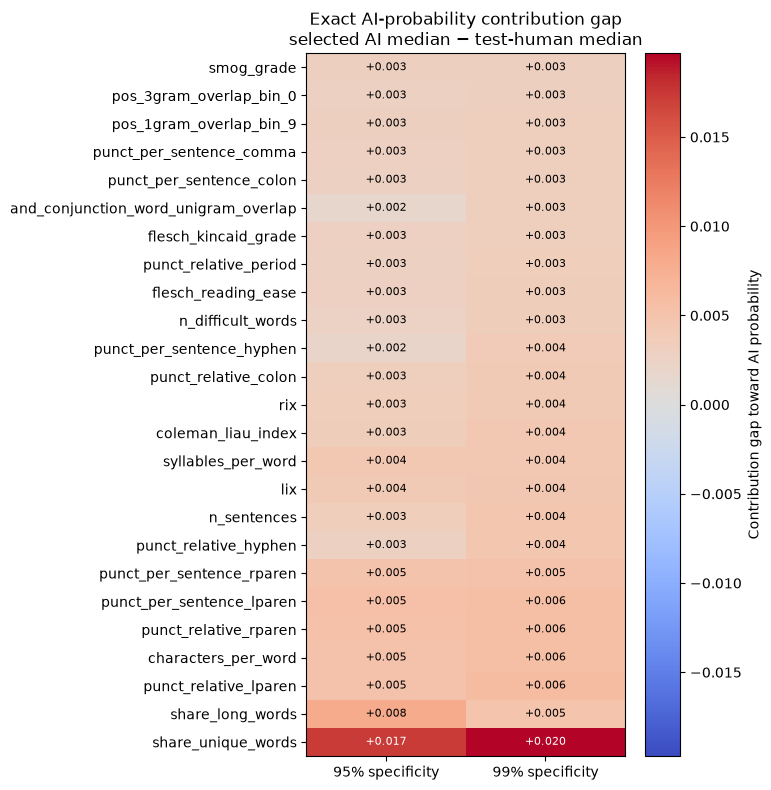

,feature,feature_block,p95,p99,max_absolute_gap
23,share_unique_words,lexical_diversity,0.017269,0.019690,0.019690
12,share_long_words,basic_relative,0.007850,0.004783,0.007850
35,punct_relative_lparen,punctuation_relative,0.005156,0.005854,0.005854
7,characters_per_word,basic_relative,0.005102,0.005689,0.005689
36,punct_relative_rparen,punctuation_relative,0.005271,0.005652,0.005652
48,punct_per_sentence_lparen,punctuation_per_sentence,0.005388,0.005607,0.005607
49,punct_per_sentence_rparen,punctuation_per_sentence,0.005024,0.005083,0.005083
33,punct_relative_hyphen,punctuation_relative,0.002701,0.004499,0.004499
3,n_sentences,basic_absolute,0.003276,0.004484,0.004484
18,lix,readability,0.003992,0.004406,0.004406


saved: ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_contribution_gap_p95_p99.png
saved: ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_contribution_gap_p95_p99.csv
saved: ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_operating_points_p95_p99.csv


In [31]:
# Exact feature-contribution gaps at 95% and 99% human specificity.
# Thresholds are calibrated only on validation humans.

def exact_forest_probability_contributions(detector, frame):
    X_frame = frame[FEATURE_NAMES]

    if isinstance(detector, Pipeline):
        forest = detector.steps[-1][1]
        X = np.asarray(detector[:-1].transform(X_frame), dtype=float)
    else:
        forest = detector
        X = X_frame.to_numpy(float)

    if not isinstance(forest, ExtraTreesClassifier):
        raise TypeError(
            f"Expected ExtraTreesClassifier, got {type(forest).__name__}"
        )

    classes = np.asarray(forest.classes_)
    ai_positions = np.flatnonzero(classes == 1)
    if len(ai_positions) != 1:
        raise ValueError(f"Could not identify AI class 1 in {classes}")
    ai_position = int(ai_positions[0])
    X = np.asarray(X, dtype=np.float32)
    contributions = np.zeros((len(X), X.shape[1]), dtype=float)
    root_bias = 0.0

    for estimator in tqdm(
        forest.estimators_,
        desc="exact forest contributions",
    ):
        tree = estimator.tree_
        values = tree.value[:, 0, :].astype(float)
        totals = values.sum(axis=1)

        node_probability = np.divide(
            values[:, ai_position],
            totals,
            out=np.zeros(len(values), dtype=float),
            where=totals != 0,
        )

        path = estimator.decision_path(X)
        root_bias += node_probability[0]

        for row_index in range(len(X)):
            nodes = path.indices[
                path.indptr[row_index]:path.indptr[row_index + 1]
            ]

            for parent in nodes:
                feature_index = tree.feature[parent]
                if feature_index < 0:
                    continue

                if X[row_index, feature_index] <= tree.threshold[parent]:
                    child = tree.children_left[parent]
                else:
                    child = tree.children_right[parent]

                contributions[row_index, feature_index] += (
                    node_probability[child] - node_probability[parent]
                )

    root_bias /= len(forest.estimators_)
    contributions /= len(forest.estimators_)

    predicted = detector.predict_proba(X_frame)[:, 1]
    reconstructed = root_bias + contributions.sum(axis=1)

    reconstruction_error = float(
        np.max(np.abs(predicted - reconstructed))
    )
    print("maximum reconstruction error:", reconstruction_error)
    assert reconstruction_error < 1e-10

    return root_bias, contributions, predicted


explanation_frame = pd.concat(
    [valid_df, test_df],
    ignore_index=True,
)

root_bias, all_contributions, all_probabilities = (
    exact_forest_probability_contributions(
        frozen_detector,
        explanation_frame,
    )
)

n_validation = len(valid_df)

validation_probabilities = all_probabilities[:n_validation]
test_probabilities = all_probabilities[n_validation:]
test_contributions = all_contributions[n_validation:]

validation_labels = valid_df["label"].to_numpy(int)
test_labels = test_df["label"].to_numpy(int)

validation_human_probabilities = validation_probabilities[
    validation_labels == 0
]
test_human = test_labels == 0
test_ai = test_labels == 1

# Common human contribution reference for both operating points.
human_reference = np.median(
    test_contributions[test_human],
    axis=0,
)

gap_columns = {}
summary_rows = []

for percentile in (95, 99):
    threshold = float(
        np.quantile(
            validation_human_probabilities,
            percentile / 100,
        )
    )

    selected_ai = test_ai & (test_probabilities >= threshold)
    if not selected_ai.any():
        raise RuntimeError(
            f"No test AI rows exceeded the p{percentile} threshold."
        )

    selected_ai_reference = np.median(
        test_contributions[selected_ai],
        axis=0,
    )
    gap_columns[f"p{percentile}"] = (
        selected_ai_reference - human_reference
    )

    summary_rows.append({
        "human_specificity_target": percentile / 100,
        "validation_human_threshold": threshold,
        "test_human_false_positive_rate": float(
            np.mean(test_probabilities[test_human] >= threshold)
        ),
        "test_ai_recall": float(
            np.mean(test_probabilities[test_ai] >= threshold)
        ),
        "selected_test_ai": int(selected_ai.sum()),
        "total_test_ai": int(test_ai.sum()),
    })

operating_summary = pd.DataFrame(summary_rows)
display(operating_summary)

feature_to_block = {
    FEATURE_NAMES[index]: block
    for block, indices in FEATURE_BLOCKS.items()
    for index in indices
}

contribution_gap = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "feature_block": [
        feature_to_block.get(feature, "unknown")
        for feature in FEATURE_NAMES
    ],
    **gap_columns,
})

contribution_gap["max_absolute_gap"] = contribution_gap[
    ["p95", "p99"]
].abs().max(axis=1)

plot_table = (
    contribution_gap
    .sort_values("max_absolute_gap", ascending=False)
    .head(25)
    .sort_values("max_absolute_gap")
    .reset_index(drop=True)
)

matrix = plot_table[["p95", "p99"]].to_numpy()
color_limit = float(np.abs(matrix).max())

fig, axis = plt.subplots(
    figsize=(7.5, max(7, 0.32 * len(plot_table)))
)

image = axis.imshow(
    matrix,
    aspect="auto",
    cmap="coolwarm",
    vmin=-color_limit,
    vmax=color_limit,
)

axis.set_xticks(
    [0, 1],
    ["95% specificity", "99% specificity"],
)
axis.set_yticks(
    np.arange(len(plot_table)),
    plot_table["feature"],
)
axis.set_title(
    "Exact AI-probability contribution gap\n"
    "selected AI median − test-human median"
)

for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]
        text_color = (
            "white"
            if abs(value) > 0.55 * color_limit
            else "black"
        )
        axis.text(
            column,
            row,
            f"{value:+.3f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8,
        )

colorbar = fig.colorbar(image, ax=axis)
colorbar.set_label(
    "Contribution gap toward AI probability"
)

fig.tight_layout()

figure_path = OUT / "fz118_contribution_gap_p95_p99.png"
table_path = OUT / "fz118_contribution_gap_p95_p99.csv"
summary_path = OUT / "fz118_operating_points_p95_p99.csv"

fig.savefig(figure_path, dpi=200, bbox_inches="tight")
contribution_gap.to_csv(table_path, index=False)
operating_summary.to_csv(summary_path, index=False)

plt.show()
display(
    contribution_gap.sort_values(
        "max_absolute_gap",
        ascending=False,
    ).head(25)
)

print("saved:", figure_path)
print("saved:", table_path)
print("saved:", summary_path)

In [28]:
# Print one representative human–AI test pair from Ghostbuster and RAID.
# Representative = pair closest to the dataset's median human and AI scores.

MAX_PRINT_CHARACTERS = 4000  # Set to None to print complete documents.

inspection = test_df[
    [
        "source_id",
        "pair_id",
        "dataset",
        "domain",
        "generator",
        "label",
        "class_name",
        "n_characters",
        "n_words",
        "n_sentences",
        "n_paragraphs",
        "mean_paragraph_words",
    ]
].copy()

inspection["ai_probability"] = frozen_detector.predict_proba(
    test_df[FEATURE_NAMES]
)[:, 1]

selected_pair_ids = []

for dataset in ["ghostbuster", "raid"]:
    dataset_rows = inspection[inspection["dataset"].eq(dataset)]

    pair_scores = dataset_rows.pivot(
        index="pair_id",
        columns="label",
        values="ai_probability",
    ).dropna()

    human_median = pair_scores[0].median()
    ai_median = pair_scores[1].median()

    pair_scores["distance_from_medians"] = (
        (pair_scores[0] - human_median).abs()
        + (pair_scores[1] - ai_median).abs()
    )

    selected_pair_ids.append(
        pair_scores["distance_from_medians"].idxmin()
    )

sample_metadata = (
    inspection[inspection["pair_id"].isin(selected_pair_ids)]
    .sort_values(["dataset", "pair_id", "label"])
)

display(sample_metadata)

for pair_id in selected_pair_ids:
    pair_metadata = sample_metadata[
        sample_metadata["pair_id"].eq(pair_id)
    ].sort_values("label")

    dataset = pair_metadata["dataset"].iloc[0]
    domain = pair_metadata["domain"].iloc[0]
    generator = pair_metadata["generator"].iloc[0]

    print("\n" + "=" * 100)
    print(
        f"{dataset.upper()} | domain={domain} | "
        f"generator={generator} | pair_id={pair_id}"
    )
    print("=" * 100)

    for row in pair_metadata.itertuples(index=False):
        corpus_row = corpus.loc[
            corpus["source_id"].eq(row.source_id)
        ].iloc[0]

        text = str(corpus_row["text"])
        truncated = (
            MAX_PRINT_CHARACTERS is not None
            and len(text) > MAX_PRINT_CHARACTERS
        )
        shown_text = (
            text[:MAX_PRINT_CHARACTERS]
            if truncated
            else text
        )

        print(
            f"\n--- {row.class_name.upper()} ---\n"
            f"AI probability: {row.ai_probability:.4f}\n"
            f"Characters: {row.n_characters}\n"
            f"Words: {row.n_words}\n"
            f"Sentences: {row.n_sentences}\n"
            f"Paragraphs: {row.n_paragraphs}\n"
            f"Mean paragraph words: {row.mean_paragraph_words:.2f}\n"
        )
        print(shown_text)

        if truncated:
            print(
                f"\n[truncated at {MAX_PRINT_CHARACTERS:,} of "
                f"{len(text):,} characters]"
            )

,source_id,pair_id,dataset,domain,generator,label,class_name,n_characters,n_words,n_sentences,n_paragraphs,mean_paragraph_words,ai_probability
158,human__ghostbuster:essay/301,79,ghostbuster,student_essay,claude,0,human,3211.0,578.0,30.0,1.0,578.0,0.297854
159,ai__ghostbuster:essay/301,79,ghostbuster,student_essay,claude,1,ai,3558.0,532.0,24.0,1.0,532.0,0.767720
3060,human__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,1530,raid,recipes,llama-chat,0,human,1658.0,275.0,14.0,1.0,275.0,0.434627
3061,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,1530,raid,recipes,llama-chat,1,ai,1572.0,249.0,15.0,1.0,249.0,0.604739



GHOSTBUSTER | domain=student_essay | generator=claude | pair_id=79

--- HUMAN ---
AI probability: 0.2979
Characters: 3211.0
Words: 578.0
Sentences: 30.0
Paragraphs: 1.0
Mean paragraph words: 578.00

Lady Mary
Lady Mary Wroth was a member of a distinguished literary family during the Renaissance. She was the niece of Mary Herbert, an eminent writer and patron during the 16th century. Mary married Robert Roth, but their marriage was unhappy. In the meantime, Lady Mary began to vent her grief with the help of poetry. Thus, her sonnet In this strange labyrinth represents the author’s throwing about the mysteries that love keeps. The significance of Lady Mary for literature is that she was the first female poet in England to write a complete sequence of sonnets called from Pamphilia to Amphilanthus.
“In this strange Labyrinth how shall I turn/Ways are on all sides”
The image of one who is lost in the labyrinth of love and is desperately looking for a way out is common in the sonnets of the

In [29]:
# Select the model family using RAID train/validation only.
raid_train = features[
    features["dataset"].eq("raid")
    & features["split"].eq("train")
].copy()

raid_validation = features[
    features["dataset"].eq("raid")
    & features["split"].eq("validation")
].copy()

raid_test = features[
    features["dataset"].eq("raid")
    & features["split"].eq("test")
].copy()

ghostbuster_test = features[
    features["dataset"].eq("ghostbuster")
    & features["split"].eq("test")
].copy()


def evaluate_feature_model(
    detector,
    frame,
    evaluation,
    feature_names=FEATURE_NAMES,
):
    probability = detector.predict_proba(
        frame[feature_names]
    )[:, 1]

    return {
        "evaluation": evaluation,
        "n": len(frame),
        "auc": roc_auc_score(frame["label"], probability),
        "accuracy": accuracy_score(
            frame["label"],
            probability >= 0.5,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            frame["label"],
            probability >= 0.5,
        ),
        "mean_human_probability": float(
            probability[frame["label"].to_numpy() == 0].mean()
        ),
        "mean_ai_probability": float(
            probability[frame["label"].to_numpy() == 1].mean()
        ),
    }


raid_validation_rows = []

for name, template in detector_candidates.items():
    detector = clone(template)
    detector.fit(
        raid_train[FEATURE_NAMES],
        raid_train["label"],
    )

    result = evaluate_feature_model(
        detector,
        raid_validation,
        name,
    )

    raid_validation_rows.append({
        "detector": name,
        "validation_auc": result["auc"],
        "validation_balanced_accuracy": (
            result["balanced_accuracy"]
        ),
    })

raid_validation_summary = (
    pd.DataFrame(raid_validation_rows)
    .sort_values(
        ["validation_auc", "validation_balanced_accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

RAID_FROZEN_DETECTOR_NAME = str(
    raid_validation_summary.iloc[0]["detector"]
)

display(raid_validation_summary)
print("RAID-selected detector:", RAID_FROZEN_DETECTOR_NAME)

# After model-family selection, use RAID train + validation.
raid_fit = pd.concat(
    [raid_train, raid_validation],
    ignore_index=True,
)

raid_detector = clone(
    detector_candidates[RAID_FROZEN_DETECTOR_NAME]
)

raid_detector.fit(
    raid_fit[FEATURE_NAMES],
    raid_fit["label"],
)

raid_evaluation_rows = [
    evaluate_feature_model(
        raid_detector,
        raid_test,
        "raid_test",
    ),
    evaluate_feature_model(
        raid_detector,
        ghostbuster_test,
        "ghostbuster_external_test",
    ),
]

# Strict leave-one-RAID-domain-out transfer.
for heldout_domain in sorted(raid_test["domain"].unique()):
    fold_train = raid_fit[
        ~raid_fit["domain"].eq(heldout_domain)
    ]
    fold_test = raid_test[
        raid_test["domain"].eq(heldout_domain)
    ]

    if (
        fold_train["label"].nunique() < 2
        or fold_test["label"].nunique() < 2
    ):
        continue

    fold_detector = clone(
        detector_candidates[RAID_FROZEN_DETECTOR_NAME]
    )
    fold_detector.fit(
        fold_train[FEATURE_NAMES],
        fold_train["label"],
    )

    raid_evaluation_rows.append(
        evaluate_feature_model(
            fold_detector,
            fold_test,
            f"raid_leave_domain_out__{heldout_domain}",
        )
    )

raid_evaluation_summary = pd.DataFrame(
    raid_evaluation_rows
)

display(raid_evaluation_summary)

with (OUT / "fz118_raid_detector.pkl").open("wb") as handle:
    pickle.dump(raid_detector, handle)

raid_validation_summary.to_csv(
    OUT / "raid_detector_validation.csv",
    index=False,
)

raid_evaluation_summary.to_csv(
    OUT / "raid_detector_evaluation.csv",
    index=False,
)

raid_detector_manifest = {
    "training_dataset": "raid",
    "training_splits": ["train", "validation"],
    "model_selection_dataset": "raid",
    "model_selection_split": "validation",
    "external_validation_dataset": "ghostbuster",
    "frozen_detector_name": RAID_FROZEN_DETECTOR_NAME,
    "feature_count": len(FEATURE_NAMES),
    "feature_contract": "FZ-118 complete",
    "layout_normalization": LAYOUT_NORMALIZATION_VERSION,
    "raid_train_validation_rows": len(raid_fit),
    "raid_test_rows": len(raid_test),
    "ghostbuster_external_test_rows": len(ghostbuster_test),
    "corpus_sha256": corpus_fingerprint,
}

with (OUT / "raid_detector_manifest.json").open("w") as handle:
    json.dump(
        raid_detector_manifest,
        handle,
        indent=2,
    )

print("saved:", OUT / "fz118_raid_detector.pkl")
print("Use raid_detector for subsequent C02e work.")

,detector,validation_auc,validation_balanced_accuracy
0,extra_trees,0.871934,0.770370
1,mlp,0.808230,0.770370
2,logistic,0.780521,0.725926


RAID-selected detector: extra_trees


,evaluation,n,auc,accuracy,balanced_accuracy,mean_human_probability,mean_ai_probability
0,raid_test,276,0.850189,0.764493,0.764493,0.432984,0.589268
1,ghostbuster_external_test,190,0.667147,0.605263,0.605263,0.465022,0.539208
2,raid_leave_domain_out__abstracts,46,0.731569,0.673913,0.673913,0.494620,0.578692
3,raid_leave_domain_out__books,36,0.743827,0.638889,0.638889,0.506816,0.585232
4,raid_leave_domain_out__news,50,0.648000,0.580000,0.580000,0.554957,0.605120
5,raid_leave_domain_out__poetry,20,0.540000,0.550000,0.550000,0.467696,0.510552
6,raid_leave_domain_out__recipes,42,0.634921,0.595238,0.595238,0.413671,0.443945
7,raid_leave_domain_out__reddit,32,0.703125,0.687500,0.687500,0.509164,0.561400
8,raid_leave_domain_out__reviews,12,0.388889,0.250000,0.250000,0.516669,0.477205
9,raid_leave_domain_out__wiki,38,0.783934,0.631579,0.631579,0.447868,0.535241


saved: ../results/causal/C02d2_fz118_ghostbuster_raid/fz118_raid_detector.pkl
Use raid_detector for subsequent C02e work.


In [30]:
PARENTHESIS_FEATURES = [
    "punct_relative_lparen",
    "punct_relative_rparen",
    "punct_per_sentence_lparen",
    "punct_per_sentence_rparen",
]

assert set(PARENTHESIS_FEATURES).issubset(FEATURE_NAMES)

# Direct distribution audit.
parenthesis_audit_rows = []

for (dataset, split), frame in features.groupby(
    ["dataset", "split"]
):
    for feature in PARENTHESIS_FEATURES:
        human = frame.loc[
            frame["label"].eq(0),
            feature,
        ].to_numpy(float)

        ai = frame.loc[
            frame["label"].eq(1),
            feature,
        ].to_numpy(float)

        pooled_sd = np.sqrt(
            (
                human.var(ddof=1)
                + ai.var(ddof=1)
            )
            / 2
        )

        smd = (
            float((ai.mean() - human.mean()) / pooled_sd)
            if pooled_sd > 0
            else 0.0
        )

        parenthesis_audit_rows.append({
            "dataset": dataset,
            "split": split,
            "feature": feature,
            "human_mean": human.mean(),
            "ai_mean": ai.mean(),
            "standardized_mean_difference": smd,
        })

parenthesis_audit = pd.DataFrame(
    parenthesis_audit_rows
)

display(parenthesis_audit)

# Raw prevalence: how often does a document contain parentheses?
parenthesis_prevalence = corpus[
    [
        "source_id",
        "dataset",
        "split",
        "class_name",
        "text",
    ]
].copy()

parenthesis_prevalence["has_parenthesis"] = (
    parenthesis_prevalence["text"]
    .astype(str)
    .str.contains(r"[()]")
)

parenthesis_prevalence_summary = (
    parenthesis_prevalence
    .groupby(
        ["dataset", "split", "class_name"]
    )["has_parenthesis"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "prevalence"})
    .reset_index()
)

display(parenthesis_prevalence_summary)

# Can the four parenthesis coordinates detect AI by themselves?
parenthesis_probe = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            C=1.0,
            max_iter=5000,
            random_state=SEED,
        ),
    ),
])

parenthesis_probe.fit(
    raid_train[PARENTHESIS_FEATURES],
    raid_train["label"],
)

parenthesis_probe_results = pd.DataFrame([
    evaluate_feature_model(
        parenthesis_probe,
        raid_validation,
        "parentheses_only__raid_validation",
        PARENTHESIS_FEATURES,
    ),
    evaluate_feature_model(
        parenthesis_probe,
        raid_test,
        "parentheses_only__raid_test",
        PARENTHESIS_FEATURES,
    ),
    evaluate_feature_model(
        parenthesis_probe,
        ghostbuster_test,
        "parentheses_only__ghostbuster_external",
        PARENTHESIS_FEATURES,
    ),
])

display(parenthesis_probe_results)

# Retrain the same RAID-selected model family without parentheses.
NO_PARENTHESIS_FEATURES = [
    feature
    for feature in FEATURE_NAMES
    if feature not in PARENTHESIS_FEATURES
]

raid_no_parenthesis_detector = clone(
    detector_candidates[RAID_FROZEN_DETECTOR_NAME]
)

raid_no_parenthesis_detector.fit(
    raid_fit[NO_PARENTHESIS_FEATURES],
    raid_fit["label"],
)

ablation_rows = [
    {
        "feature_set": "full_fz118",
        **evaluate_feature_model(
            raid_detector,
            raid_test,
            "raid_test",
            FEATURE_NAMES,
        ),
    },
    {
        "feature_set": "without_parentheses",
        **evaluate_feature_model(
            raid_no_parenthesis_detector,
            raid_test,
            "raid_test",
            NO_PARENTHESIS_FEATURES,
        ),
    },
    {
        "feature_set": "full_fz118",
        **evaluate_feature_model(
            raid_detector,
            ghostbuster_test,
            "ghostbuster_external_test",
            FEATURE_NAMES,
        ),
    },
    {
        "feature_set": "without_parentheses",
        **evaluate_feature_model(
            raid_no_parenthesis_detector,
            ghostbuster_test,
            "ghostbuster_external_test",
            NO_PARENTHESIS_FEATURES,
        ),
    },
]

# Repeat leave-one-domain-out under the ablation.
for heldout_domain in sorted(raid_test["domain"].unique()):
    fold_train = raid_fit[
        ~raid_fit["domain"].eq(heldout_domain)
    ]
    fold_test = raid_test[
        raid_test["domain"].eq(heldout_domain)
    ]

    if (
        fold_train["label"].nunique() < 2
        or fold_test["label"].nunique() < 2
    ):
        continue

    full_fold_detector = clone(
        detector_candidates[RAID_FROZEN_DETECTOR_NAME]
    )
    full_fold_detector.fit(
        fold_train[FEATURE_NAMES],
        fold_train["label"],
    )

    ablated_fold_detector = clone(
        detector_candidates[RAID_FROZEN_DETECTOR_NAME]
    )
    ablated_fold_detector.fit(
        fold_train[NO_PARENTHESIS_FEATURES],
        fold_train["label"],
    )

    evaluation_name = (
        f"raid_leave_domain_out__{heldout_domain}"
    )

    ablation_rows.extend([
        {
            "feature_set": "full_fz118",
            **evaluate_feature_model(
                full_fold_detector,
                fold_test,
                evaluation_name,
                FEATURE_NAMES,
            ),
        },
        {
            "feature_set": "without_parentheses",
            **evaluate_feature_model(
                ablated_fold_detector,
                fold_test,
                evaluation_name,
                NO_PARENTHESIS_FEATURES,
            ),
        },
    ])

parenthesis_ablation = pd.DataFrame(ablation_rows)

parenthesis_ablation["auc_change_without_parentheses"] = (
    parenthesis_ablation
    .groupby("evaluation")["auc"]
    .transform(
        lambda values: (
            values.iloc[-1] - values.iloc[0]
            if len(values) == 2
            else np.nan
        )
    )
)

display(
    parenthesis_ablation.sort_values(
        ["evaluation", "feature_set"]
    )
)

parenthesis_audit.to_csv(
    OUT / "parenthesis_feature_audit.csv",
    index=False,
)

parenthesis_prevalence_summary.to_csv(
    OUT / "parenthesis_prevalence.csv",
    index=False,
)

parenthesis_probe_results.to_csv(
    OUT / "parenthesis_only_probe.csv",
    index=False,
)

parenthesis_ablation.to_csv(
    OUT / "raid_parenthesis_ablation.csv",
    index=False,
)

,dataset,split,feature,human_mean,ai_mean,standardized_mean_difference
0,ghostbuster,test,punct_relative_lparen,0.000678,0.000107,-0.957480
1,ghostbuster,test,punct_relative_rparen,0.000807,0.000107,-0.681119
2,ghostbuster,test,punct_per_sentence_lparen,0.092480,0.014482,-0.910093
3,ghostbuster,test,punct_per_sentence_rparen,0.101502,0.014482,-0.854597
4,ghostbuster,train,punct_relative_lparen,0.000750,0.000136,-0.853884
5,ghostbuster,train,punct_relative_rparen,0.000749,0.000178,-0.771766
6,ghostbuster,train,punct_per_sentence_lparen,0.099276,0.019078,-0.804322
7,ghostbuster,train,punct_per_sentence_rparen,0.099014,0.025216,-0.717353
8,ghostbuster,validation,punct_relative_lparen,0.000658,0.000133,-0.849747
9,ghostbuster,validation,punct_relative_rparen,0.000661,0.000162,-0.779287


,dataset,split,class_name,count,prevalence
0,ghostbuster,test,ai,95,0.126316
1,ghostbuster,test,human,95,0.621053
2,ghostbuster,train,ai,447,0.174497
3,ghostbuster,train,human,447,0.563758
4,ghostbuster,validation,ai,96,0.166667
5,ghostbuster,validation,human,96,0.562500
6,raid,test,ai,138,0.456522
7,raid,test,human,138,0.471014
8,raid,train,ai,636,0.438679
9,raid,train,human,636,0.523585


,evaluation,n,auc,accuracy,balanced_accuracy,mean_human_probability,mean_ai_probability
0,parentheses_only__raid_validation,270,0.516379,0.537037,0.537037,0.497182,0.502596
1,parentheses_only__raid_test,276,0.513338,0.539855,0.539855,0.496633,0.503835
2,parentheses_only__ghostbuster_external,190,0.657064,0.673684,0.673684,0.493107,0.515349


,feature_set,evaluation,n,auc,accuracy,balanced_accuracy,mean_human_probability,mean_ai_probability,auc_change_without_parentheses
2,full_fz118,ghostbuster_external_test,190,0.667147,0.605263,0.605263,0.465022,0.539208,-7.745152e-02
3,without_parentheses,ghostbuster_external_test,190,0.589695,0.542105,0.542105,0.492741,0.531922,-7.745152e-02
4,full_fz118,raid_leave_domain_out__abstracts,46,0.731569,0.673913,0.673913,0.494620,0.578692,-1.096408e-01
5,without_parentheses,raid_leave_domain_out__abstracts,46,0.621928,0.630435,0.630435,0.533161,0.576811,-1.096408e-01
6,full_fz118,raid_leave_domain_out__books,36,0.743827,0.638889,0.638889,0.506816,0.585232,-4.012346e-02
7,without_parentheses,raid_leave_domain_out__books,36,0.703704,0.638889,0.638889,0.503823,0.564165,-4.012346e-02
8,full_fz118,raid_leave_domain_out__news,50,0.648000,0.580000,0.580000,0.554957,0.605120,3.520000e-02
9,without_parentheses,raid_leave_domain_out__news,50,0.683200,0.580000,0.580000,0.538130,0.584811,3.520000e-02
10,full_fz118,raid_leave_domain_out__poetry,20,0.540000,0.550000,0.550000,0.467696,0.510552,-5.000000e-02
11,without_parentheses,raid_leave_domain_out__poetry,20,0.490000,0.450000,0.450000,0.471598,0.496338,-5.000000e-02


In [32]:
raid_detector = raid_no_parenthesis_detector
RAID_MODEL_FEATURES = NO_PARENTHESIS_FEATURES

with (OUT / "fz118_raid_detector.pkl").open("wb") as handle:
    pickle.dump(raid_detector, handle)

with (OUT / "fz118_raid_feature_names.json").open("w") as handle:
    json.dump(RAID_MODEL_FEATURES, handle, indent=2)

print("final detector: RAID-only ExtraTrees without parenthesis features")
print("features:", len(RAID_MODEL_FEATURES))

final detector: RAID-only ExtraTrees without parenthesis features
features: 114
